# TCAV: Testing with Concept Activation Vectors
### Target data: ImageNette · Concept data: DTD (Describable Textures) · Model: fine-tuned ResNet50 · Framework: PyTorch

**Objective.** Test whether the predictions of an image classifier for a target class $k$ are *sensitive* to a human-understandable concept $C$ (e.g. "dotted"), using our own implementation of TCAV (Kim et al., 2018):

1. Fine-tune ResNet50 on ImageNette (10 classes) and evaluate it on a held-out test set.
2. Take an intermediate representation $f(x)$ (global-average-pooled `layer4` → 2048-d; optionally `layer3` → 1024-d).
3. Train a linear classifier separating concept images (DTD) from non-concept reference images in that feature space. Its (unit-normalised) weight vector is the CAV $v_C$.
4. Compute directional derivatives $S_{C,k}(x)=\nabla_{f(x)}h_k(f(x))\cdot v_C$ with autograd through the *downstream* part of the network.
5. TCAV score = fraction of class-$k$ images with $S_{C,k}(x)>0$.
6. Compare against random CAV controls with repeated runs and a multiple-comparison-corrected statistical test.

> **How to run (Colab):** Runtime → Change runtime type → GPU, then *Run all* (or run top to bottom). Nothing in this notebook has been executed yet; all numbers will be produced when you run it.

> **Important mathematical note (read before interpreting results).** For *pooled `layer4`* features the downstream network is just the linear head, $h_k(p)=w_k^\top p+b_k$, so $\nabla_p h_k = w_k$ is **the same for every image**. Then $S_{C,k}(x)=w_k^\top v_C$ has the same sign for all $x$ and a single CAV gives a TCAV score of exactly 0 or 1. The implementation below is still correct and is run as requested, but the notebook also (i) uses repeated CAVs, so the mean TCAV score over runs becomes "the fraction of CAVs with $w_k^\top v_C>0$", (ii) reports the continuous mean directional derivative, and (iii) includes `layer3` (pooled), whose downstream path contains the non-linear `layer4` block so gradients genuinely vary across images. A check cell reports this numerically.

## 2. Imports and environment setup
Colab already ships `torch`/`torchvision`; we only install small extras. No TCAV library is used anywhere.

In [35]:
%pip install -q seaborn statsmodels scikit-learn tqdm requests

In [36]:
import os, sys, json, math, random, time, copy, tarfile, shutil, warnings
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display
import requests

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from scipy import stats
from statsmodels.stats.multitest import multipletests

print("torch", torch.__version__, "| torchvision", torchvision.__version__)

torch 2.14.1+cu130 | torchvision 0.29.1+cu130


In [37]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("WARNING: no GPU found. Fine-tuning and feature extraction will be very slow. In Colab: Runtime -> Change runtime type -> GPU.")

Device: cuda
GPU: Tesla T4
GPU memory: 15.6 GB


## 3. Configuration and reproducibility
All tunable settings live in one `CFG` class. **`CFG.PILOT = True`** (default) overrides `EPOCHS`, `N_CAV_RUNS` and `N_RANDOM_RUNS` with small values for a quick end-to-end check; set it to `False` for the final run. Scale `N_CAV_RUNS`, `N_RANDOM_RUNS`, `EPOCHS`, `BATCH_SIZE`, `NUM_WORKERS` up or down as needed.

**Concept–class hypotheses** are pre-specified guesses about plausible visual links; they are *not* expected results. The first three come from the project brief; `zigzagged → chain saw` (saw teeth) and `woven → cassette player` (speaker-grille/mesh look) are weaker guesses. All 47 DTD category names were checked against the DTD paper's vocabulary: `dotted`, `striped`, `banded`, `zigzagged`, `woven` all exist (DTD has **no** "metallic" category). The notebook re-verifies the names against the downloaded files.

In [38]:
class CFG:
    SEED = 42
    ON_COLAB = "google.colab" in sys.modules
    WORK_DIR = Path("/content") if ON_COLAB else Path.cwd()
    DATA_DIR = WORK_DIR / "tcav_data"
    OUT_DIR = WORK_DIR / "tcav_outputs"
    SAVE_TO_DRIVE = True
    DRIVE_DIR = "/content/drive/MyDrive/TCAV_ImageNette_DTD"
    IMAGENETTE_URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
    DTD_URL = "https://www.robots.ox.ac.uk/~vgg/data/dtd/download/dtd-r1.0.1.tar.gz"
    VAL_FRACTION = 0.10
    RESIZE = 256
    IMG_SIZE = 224
    MEAN = (0.485, 0.456, 0.406)
    STD = (0.229, 0.224, 0.225)
    BATCH_SIZE = 64
    NUM_WORKERS = 2
    EPOCHS = 6
    LR = 1e-4
    WEIGHT_DECAY = 1e-4
    LABEL_SMOOTHING = 0.0
    PATIENCE = 3
    USE_AMP = True
    FORCE_RETRAIN = False
    PILOT = False
    CONCEPTS = ["dotted", "striped", "banded", "zigzagged", "woven"]
    CONCEPT_CLASS_HYPOTHESES = {
        "dotted": "golf ball",
        "striped": "English springer",
        "banded": "parachute",
        "zigzagged": "chain saw",
        "woven": "cassette player",
    }
    N_CONCEPT_IMGS = 120
    REFERENCE_SOURCE = "dtd_other"
    REF_POOL_SIZE = 1500
    EXTRA_EXCLUDE = ["polka-dotted", "lined", "stratified", "crosshatched"]
    TCAV_LAYERS = ["layer4", "layer3"]
    PRIMARY_LAYER = "layer3"
    TCAV_BATCH_SIZE = 64
    TCAV_ONLY_CORRECT = False
    CAV_VAL_FRAC = 0.20
    CAV_STEPS = 200
    CAV_LR = 0.02
    CAV_L2 = 1e-2
    CAV_MIN_ACC = 0.70
    N_CAV_RUNS = 30
    N_RANDOM_RUNS = 50
    CONTROLS = ["shuffled_labels", "random_reference"]
    ALPHA = 0.05

if CFG.PILOT:
    CFG.EPOCHS, CFG.N_CAV_RUNS, CFG.N_RANDOM_RUNS = 2, 5, 10
    print(f"*** PILOT MODE: EPOCHS={CFG.EPOCHS}, N_CAV_RUNS={CFG.N_CAV_RUNS}, N_RANDOM_RUNS={CFG.N_RANDOM_RUNS}. Set CFG.PILOT=False (and re-run from this cell) for the final experiment. ***")

CFG.OUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.DATA_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(CFG.SEED)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

g_loader = torch.Generator()
g_loader.manual_seed(CFG.SEED)

use_amp = CFG.USE_AMP and device.type == "cuda"
print("Work dir:", CFG.WORK_DIR, "| AMP for fine-tuning:", use_amp)

Work dir: /content | AMP for fine-tuning: True


## 4. Dataset download and extraction
ImageNette (320px version, ~340 MB) comes from the fast.ai S3 bucket; DTD (~600 MB) from the Oxford VGG page, with a `torchvision.datasets.DTD` fallback. Downloads are skipped if the data already exists.

In [39]:
def download_file(url, dest):
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        print(f"[skip] {dest.name} already downloaded")
        return dest
    tmp = dest.with_name(dest.name + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=dest.name) as pbar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                pbar.update(len(chunk))
    tmp.rename(dest)
    return dest

def extract_tar(archive, out_dir):
    with tarfile.open(archive) as tar:
        try:
            tar.extractall(out_dir, filter="data")
        except TypeError:
            tar.extractall(out_dir)

def find_dtd_images_dir(search_roots):
    for root in search_roots:
        if not Path(root).exists():
            continue
        for cand in Path(root).rglob("images"):
            if cand.is_dir() and sum(1 for d in cand.iterdir() if d.is_dir()) == 47:
                return cand
    return None

IMAGENETTE_ROOT = CFG.DATA_DIR / "imagenette2-320"
if not (IMAGENETTE_ROOT / "train").exists():
    arc = download_file(CFG.IMAGENETTE_URL, CFG.DATA_DIR / "imagenette2-320.tgz")
    extract_tar(arc, CFG.DATA_DIR)
print("ImageNette root:", IMAGENETTE_ROOT, "| exists:", IMAGENETTE_ROOT.exists())

DTD_SEARCH_ROOTS = [CFG.DATA_DIR / "dtd", CFG.DATA_DIR / "tv_dtd"]
dtd_images_dir = find_dtd_images_dir(DTD_SEARCH_ROOTS)
if dtd_images_dir is None:
    try:
        arc = download_file(CFG.DTD_URL, CFG.DATA_DIR / "dtd-r1.0.1.tar.gz")
        extract_tar(arc, CFG.DATA_DIR)
    except Exception as e:
        print("Direct DTD download failed:", repr(e), "\n-> falling back to torchvision.datasets.DTD")
        datasets.DTD(root=str(CFG.DATA_DIR / "tv_dtd"), split="train", download=True)
    dtd_images_dir = find_dtd_images_dir(DTD_SEARCH_ROOTS)
assert dtd_images_dir is not None, "DTD images folder not found - check the download."
print("DTD images dir:", dtd_images_dir)

ImageNette root: /content/tcav_data/imagenette2-320 | exists: True
DTD images dir: /content/tcav_data/dtd/images


## 5. ImageNette dataset loading
Splits (no leakage):
* **train / val**: stratified 90/10 split of the official ImageNette `train` folder,
* **test**: the official ImageNette `val` folder (never used for fine-tuning, model selection, or CAV training).

`ImageFolder` sorts WordNet IDs, which gives the class order of the project brief.

In [40]:
IMAGENETTE_CLASSES = OrderedDict([
    ("n01440764", "tench"), ("n02102040", "English springer"), ("n02979186", "cassette player"),
    ("n03000684", "chain saw"), ("n03028079", "church"), ("n03394916", "French horn"),
    ("n03417042", "garbage truck"), ("n03425413", "gas pump"), ("n03445777", "golf ball"),
    ("n03888257", "parachute"),
])
WNIDS = list(IMAGENETTE_CLASSES.keys())
CLASS_NAMES = list(IMAGENETTE_CLASSES.values())
NUM_CLASSES = len(CLASS_NAMES)

_trainfolder = datasets.ImageFolder(IMAGENETTE_ROOT / "train")
_testfolder = datasets.ImageFolder(IMAGENETTE_ROOT / "val")
assert _trainfolder.classes == WNIDS and _testfolder.classes == WNIDS, "unexpected class folders"

trainval_paths = np.array([p for p, _ in _trainfolder.samples])
trainval_labels = np.array([l for _, l in _trainfolder.samples])

train_idx, val_idx = train_test_split(
    np.arange(len(trainval_paths)), test_size=CFG.VAL_FRACTION,
    stratify=trainval_labels, random_state=CFG.SEED)

train_paths, train_labels = trainval_paths[train_idx], trainval_labels[train_idx]
val_paths, val_labels = trainval_paths[val_idx], trainval_labels[val_idx]
test_paths = np.array([p for p, _ in _testfolder.samples])
test_labels = np.array([l for _, l in _testfolder.samples])

assert set(train_paths).isdisjoint(val_paths)
assert set(train_paths).isdisjoint(test_paths) and set(val_paths).isdisjoint(test_paths)
print(f"train {len(train_paths)} | val {len(val_paths)} | test {len(test_paths)}")

test_paths_by_class = {k: [p for p, l in zip(test_paths, test_labels) if l == k] for k in range(NUM_CLASSES)}
print("test images per class:", {CLASS_NAMES[k]: len(v) for k, v in test_paths_by_class.items()})

train 8522 | val 947 | test 3925
test images per class: {'tench': 387, 'English springer': 395, 'cassette player': 357, 'chain saw': 386, 'church': 409, 'French horn': 394, 'garbage truck': 389, 'gas pump': 419, 'golf ball': 399, 'parachute': 390}


## 6. DTD dataset loading
DTD has 47 texture categories (120 images each). Category names are read from the downloaded folders (not typed by hand); the chosen concepts are then checked against them.

In [41]:
dtd_categories = sorted(d.name for d in dtd_images_dir.iterdir() if d.is_dir())
dtd_paths = {c: sorted(str(p) for p in (dtd_images_dir / c).glob("*.jpg")) for c in dtd_categories}

assert len(dtd_categories) == 47, f"expected 47 DTD categories, found {len(dtd_categories)}"
print("DTD categories (read from disk):\n", dtd_categories)
print("\nImages per category: min", min(len(v) for v in dtd_paths.values()), "max", max(len(v) for v in dtd_paths.values()))

missing = [c for c in CFG.CONCEPTS if c not in dtd_categories]
assert not missing, f"concepts not in DTD: {missing}"
assert all(k in CLASS_NAMES for k in CFG.CONCEPT_CLASS_HYPOTHESES.values()), "unknown target class in hypotheses"
assert all(c in CFG.CONCEPTS for c in CFG.CONCEPT_CLASS_HYPOTHESES), "hypothesis concept not in CFG.CONCEPTS"
print("\nAll selected concepts exist in DTD:", CFG.CONCEPTS)

DTD categories (read from disk):
 ['banded', 'blotchy', 'braided', 'bubbly', 'bumpy', 'chequered', 'cobwebbed', 'cracked', 'crosshatched', 'crystalline', 'dotted', 'fibrous', 'flecked', 'freckled', 'frilly', 'gauzy', 'grid', 'grooved', 'honeycombed', 'interlaced', 'knitted', 'lacelike', 'lined', 'marbled', 'matted', 'meshed', 'paisley', 'perforated', 'pitted', 'pleated', 'polka-dotted', 'porous', 'potholed', 'scaly', 'smeared', 'spiralled', 'sprinkled', 'stained', 'stratified', 'striped', 'studded', 'swirly', 'veined', 'waffled', 'woven', 'wrinkled', 'zigzagged']

Images per category: min 120 max 120

All selected concepts exist in DTD: ['dotted', 'striped', 'banded', 'zigzagged', 'woven']


## 7. Data exploration and visualization

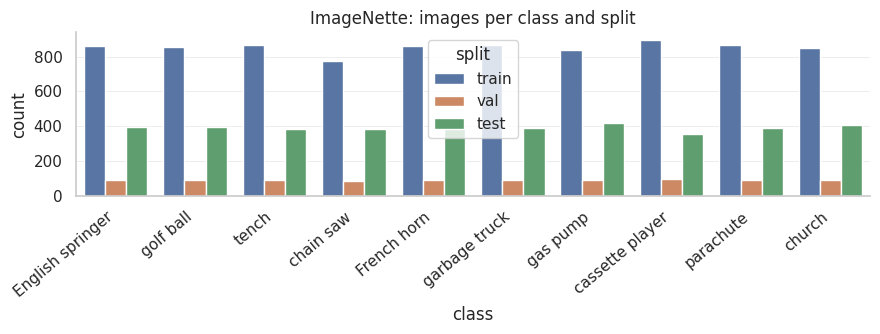

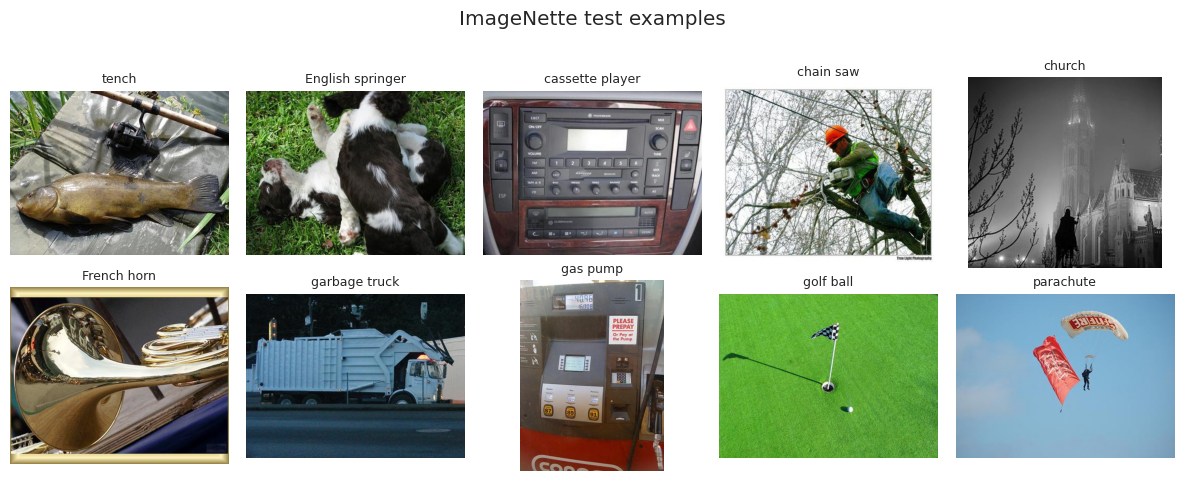

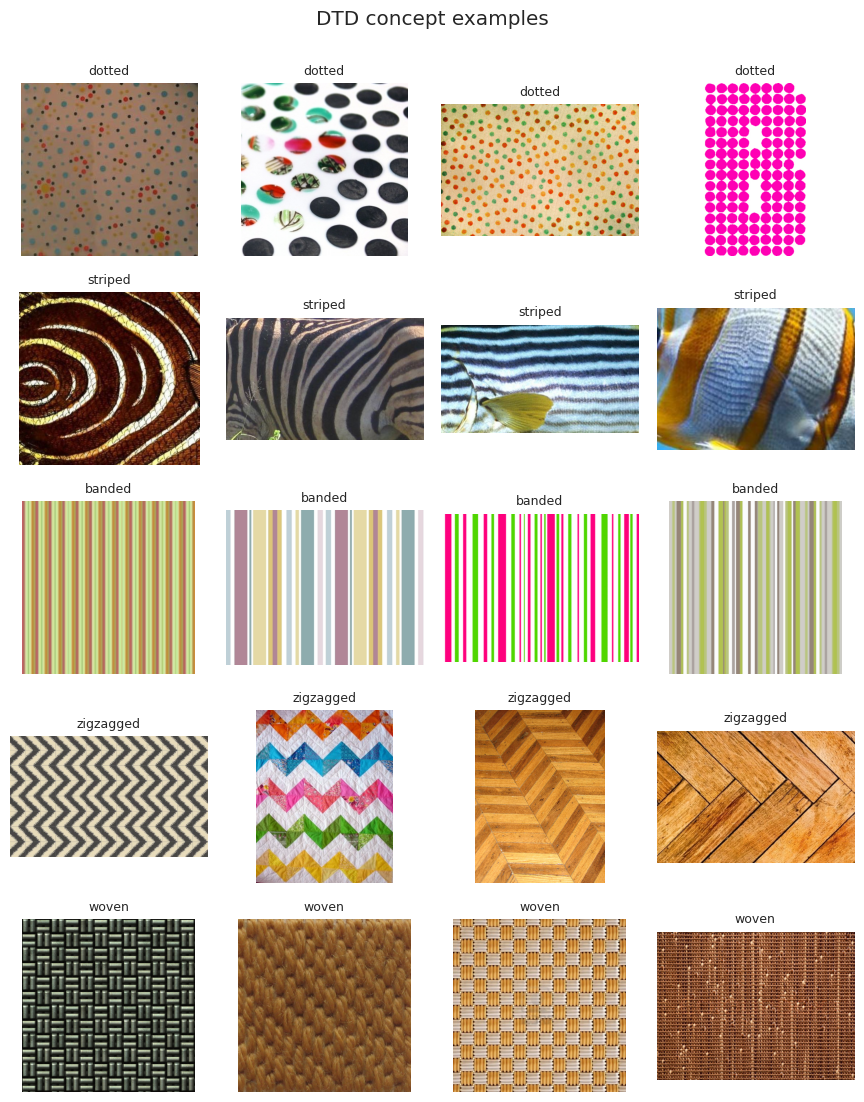

In [42]:
def show_grid(paths, titles, ncols=5, figsize_per=2.4, suptitle=None):
    n = len(paths)
    nrows = int(math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * figsize_per, nrows * figsize_per))
    axes = np.array(axes).reshape(-1)
    for ax in axes:
        ax.axis("off")
    for ax, p, t in zip(axes, paths, titles):
        ax.imshow(Image.open(p).convert("RGB"))
        ax.set_title(t, fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, y=1.0)
    plt.tight_layout()
    plt.show()

counts = pd.DataFrame({"split": ["train"] * len(train_labels) + ["val"] * len(val_labels) + ["test"] * len(test_labels),
                       "class": [CLASS_NAMES[l] for l in np.concatenate([train_labels, val_labels, test_labels])]})
plt.figure(figsize=(9, 3.5))
sns.countplot(data=counts, x="class", hue="split")
plt.xticks(rotation=40, ha="right")
plt.title("ImageNette: images per class and split")
plt.tight_layout()
plt.show()

show_grid([test_paths_by_class[k][0] for k in range(NUM_CLASSES)], CLASS_NAMES, ncols=5, suptitle="ImageNette test examples")

sel = [dtd_paths[c][i] for c in CFG.CONCEPTS for i in range(4)]
tit = [c for c in CFG.CONCEPTS for _ in range(4)]
show_grid(sel, tit, ncols=4, figsize_per=2.2, suptitle="DTD concept examples")

## 8. Image preprocessing and DataLoaders
`eval_tf` is the **single** preprocessing used for validation/test images, DTD concept images, reference images and TCAV test images, so feature spaces are consistent. Only fine-tuning uses light augmentation (`train_tf`).

In [43]:
normalize = transforms.Normalize(CFG.MEAN, CFG.STD)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(CFG.IMG_SIZE, scale=(0.35, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), normalize])
eval_tf = transforms.Compose([
    transforms.Resize(CFG.RESIZE),
    transforms.CenterCrop(CFG.IMG_SIZE),
    transforms.ToTensor(), normalize])

class ImagePathDataset(Dataset):
    def __init__(self, paths, labels=None, transform=None):
        self.paths = list(paths)
        self.labels = None if labels is None else np.asarray(labels)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        y = -1 if self.labels is None else int(self.labels[i])
        return img, y

def make_loader(ds, batch_size, shuffle=False, train=False):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=train,
                      num_workers=CFG.NUM_WORKERS, pin_memory=(device.type == "cuda"),
                      worker_init_fn=seed_worker, generator=g_loader if shuffle else None)

train_loader = make_loader(ImagePathDataset(train_paths, train_labels, train_tf), CFG.BATCH_SIZE, shuffle=True, train=True)
val_loader = make_loader(ImagePathDataset(val_paths, val_labels, eval_tf), CFG.BATCH_SIZE)
test_loader = make_loader(ImagePathDataset(test_paths, test_labels, eval_tf), CFG.BATCH_SIZE)

xb, yb = next(iter(train_loader))
print("batch:", tuple(xb.shape), xb.dtype, "| labels:", tuple(yb.shape))

batch: (64, 3, 224, 224) torch.float32 | labels: (64,)


## 9. ResNet50 model setup
Pretrained torchvision ResNet50 (ImageNet weights); the 1000-way `fc` is replaced by a 10-way linear layer. The whole network is fine-tuned.

In [44]:
def build_model(num_classes=NUM_CLASSES, pretrained=True):
    weights = models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None
    m = models.resnet50(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, num_classes)
    return m

model = build_model().to(device)
print("fc:", model.fc, "| trainable params: %.1fM" % (sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6))

fc: Linear(in_features=2048, out_features=10, bias=True) | trainable params: 23.5M


## 10. Model training
AdamW + cosine learning-rate schedule, accuracy/loss tracking, best-checkpoint selection (validation accuracy, ties broken by validation loss) and early stopping. A checkpoint stores the training history and a fingerprint of the training configuration. It is reused (training skipped) only if it finished training **and** its fingerprint matches the current `CFG`; otherwise the model is retrained, so an old model cannot be loaded silently after you change e.g. `EPOCHS`. `CFG.FORCE_RETRAIN=True` always retrains.

In [45]:
CKPT_PATH = CFG.OUT_DIR / "resnet50_imagenette_best.pt"
HIST_PATH = CFG.OUT_DIR / "training_history.json"
TRAIN_FP = {"epochs": CFG.EPOCHS, "lr": CFG.LR, "weight_decay": CFG.WEIGHT_DECAY, "batch_size": CFG.BATCH_SIZE,
            "label_smoothing": CFG.LABEL_SMOOTHING, "patience": CFG.PATIENCE, "seed": CFG.SEED,
            "val_fraction": CFG.VAL_FRACTION, "img_size": CFG.IMG_SIZE, "resize": CFG.RESIZE,
            "weights": "ResNet50_Weights.IMAGENET1K_V2", "n_train": int(len(train_paths))}

try:
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

def run_epoch(model, loader, criterion, optimizer=None, train=False):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, leave=False, desc="train" if train else "eval"):
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def train_model(model):
    criterion = nn.CrossEntropyLoss(label_smoothing=CFG.LABEL_SMOOTHING)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.EPOCHS)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
    best_acc, best_loss, bad_epochs = -1.0, float("inf"), 0
    for epoch in range(1, CFG.EPOCHS + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, train=True)
        va_loss, va_acc = run_epoch(model, val_loader, criterion, train=False)
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        scheduler.step()
        for key, val in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [tr_loss, tr_acc, va_loss, va_acc]):
            hist[key].append(val)
        better = (va_acc > best_acc + 1e-6) or (abs(va_acc - best_acc) <= 1e-6 and va_loss < best_loss)
        if better:
            best_acc, best_loss, bad_epochs = va_acc, va_loss, 0
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_acc": va_acc,
                        "val_loss": va_loss, "class_names": CLASS_NAMES, "wnids": WNIDS,
                        "train_cfg": TRAIN_FP, "history": copy.deepcopy(hist), "train_complete": False}, CKPT_PATH)
        else:
            bad_epochs += 1
        print(f"epoch {epoch:02d}/{CFG.EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | {time.time() - t0:.0f}s {'(best)' if better else ''}")
        if bad_epochs >= CFG.PATIENCE:
            print("Early stopping.")
            break
    ck = torch.load(CKPT_PATH, map_location="cpu")
    ck["history"], ck["train_complete"] = hist, True
    torch.save(ck, CKPT_PATH)
    with open(HIST_PATH, "w") as f:
        json.dump(hist, f)
    return hist

In [46]:
def checkpoint_is_reusable():
    if not CKPT_PATH.exists():
        return False, "no checkpoint found"
    ck = torch.load(CKPT_PATH, map_location="cpu")
    if not ck.get("train_complete", False):
        return False, "existing checkpoint comes from an unfinished/older run"
    if ck.get("train_cfg") != TRAIN_FP:
        return False, "existing checkpoint was trained with a different configuration"
    return True, ck

reusable, info = checkpoint_is_reusable()
if reusable and not CFG.FORCE_RETRAIN:
    print("Matching, completed checkpoint found -> skipping training (set CFG.FORCE_RETRAIN=True to retrain).")
    history = info["history"]
else:
    print("Training from scratch:", "FORCE_RETRAIN=True" if reusable else info)
    set_seed(CFG.SEED)
    model = build_model().to(device)
    history = train_model(model)

Training from scratch: no checkpoint found


train:   0%|          | 0/133 [00:00<?, ?it/s]

eval:   0%|          | 0/15 [00:00<?, ?it/s]

epoch 01/6 | train loss 0.4136 acc 0.9301 | val loss 0.0354 acc 0.9916 | 56s (best)


train:   0%|          | 0/133 [00:00<?, ?it/s]

eval:   0%|          | 0/15 [00:00<?, ?it/s]

... (9 outputs left out)

epoch 05/6 | train loss 0.0178 acc 0.9953 | val loss 0.0091 acc 0.9968 | 66s (best)


train:   0%|          | 0/133 [00:00<?, ?it/s]

eval:   0%|          | 0/15 [00:00<?, ?it/s]

epoch 06/6 | train loss 0.0171 acc 0.9953 | val loss 0.0074 acc 0.9979 | 65s (best)


## 11. Model validation and testing
The best checkpoint (by validation accuracy) is reloaded and evaluated on the validation set and the held-out test set.

In [47]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    losses, preds, labels = 0.0, [], []
    for x, y in tqdm(loader, leave=False, desc="evaluate"):
        x, y = x.to(device), y.to(device)
        logits = model(x)
        losses += criterion(logits, y).item() * x.size(0)
        preds.append(logits.argmax(1).cpu())
        labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return {"loss": losses / len(labels), "acc": float((preds == labels).mean()), "preds": preds, "labels": labels}

ckpt = torch.load(CKPT_PATH, map_location=device)
model = build_model(pretrained=False).to(device)
model.load_state_dict(ckpt["model_state"])
model.eval()
print(f"Loaded best checkpoint from epoch {ckpt['epoch']} (val acc {ckpt['val_acc']:.4f})")

val_res = evaluate(model, val_loader)
test_res = evaluate(model, test_loader)
print(f"val  loss {val_res['loss']:.4f} acc {val_res['acc']:.4f}")
print(f"test loss {test_res['loss']:.4f} acc {test_res['acc']:.4f}")

Loaded best checkpoint from epoch 6 (val acc 0.9979)


evaluate:   0%|          | 0/15 [00:00<?, ?it/s]

evaluate:   0%|          | 0/62 [00:00<?, ?it/s]

val  loss 0.0074 acc 0.9979
test loss 0.0220 acc 0.9924


## 12. Model evaluation and plots

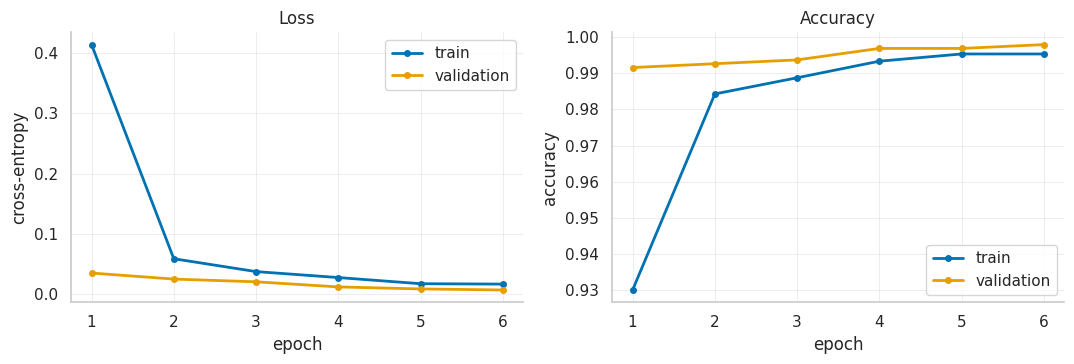

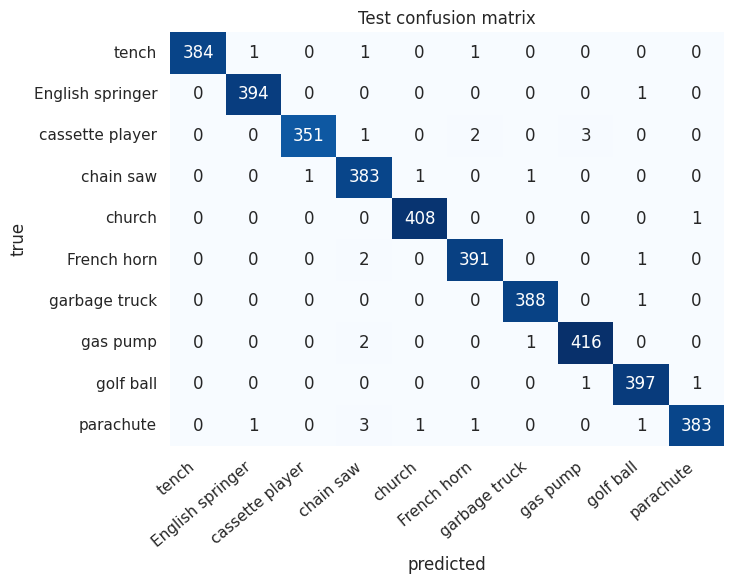

                  precision    recall  f1-score   support

           tench     1.0000    0.9922    0.9961       387
English springer     0.9949    0.9975    0.9962       395
 cassette player     0.9972    0.9832    0.9901       357
       chain saw     0.9770    0.9922    0.9846       386
          church     0.9951    0.9976    0.9963       409
     French horn     0.9899    0.9924    0.9911       394
   garbage truck     0.9949    0.9974    0.9961       389
        gas pump     0.9905    0.9928    0.9917       419
       golf ball     0.9900    0.9950    0.9925       399
       parachute     0.9948    0.9821    0.9884       390

        accuracy                         0.9924      3925
       macro avg     0.9924    0.9922    0.9923      3925
    weighted avg     0.9924    0.9924    0.9924      3925



In [48]:
sns.set_theme(style="whitegrid", rc={"grid.linewidth": 0.5, "grid.alpha": 0.5, "axes.spines.top": False, "axes.spines.right": False})
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9", "#F0E442", "#000000"]

if history is not None:
    ep = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    axes[0].plot(ep, history["train_loss"], color=OKABE[0], lw=2, marker="o", ms=4, label="train")
    axes[0].plot(ep, history["val_loss"], color=OKABE[1], lw=2, marker="o", ms=4, label="validation")
    axes[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy")
    axes[0].legend()
    axes[1].plot(ep, history["train_acc"], color=OKABE[0], lw=2, marker="o", ms=4, label="train")
    axes[1].plot(ep, history["val_acc"], color=OKABE[1], lw=2, marker="o", ms=4, label="validation")
    axes[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(CFG.OUT_DIR / "training_curves.png", dpi=200)
    plt.show()
else:
    print("No training history file found (training was skipped and no history was saved).")

cm = confusion_matrix(test_res["labels"], test_res["preds"], labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(7.5, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("Test confusion matrix")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig(CFG.OUT_DIR / "confusion_matrix.png", dpi=200)
plt.show()

print(classification_report(test_res["labels"], test_res["preds"], target_names=CLASS_NAMES, digits=4))

## 13. Intermediate feature extraction
**Design (critical for TCAV correctness).** `SplitResNet` is a transparent re-implementation of the ResNet50 forward pass split at a residual stage:

* `trunk(x, layer)` : image → activation map $A\in\mathbb{R}^{B\times C\times H\times W}$ after `layer`,
* feature $f(x)=\mathrm{GAP}(A)\in\mathbb{R}^{B\times C}$ (`layer4`: $C=2048$, `layer3`: $C=1024$),
* `downstream(A, layer)` : the *remaining* residual stages → global average pool → `fc` → logits.

CAV training uses $f(x)$ from `trunk`; the directional derivative (section 19) differentiates the logits of `downstream` with respect to this *same* $f(x)$. Equivalence with the original `model(x)` and with forward hooks is verified below.

In [49]:
LAYER_ORDER = ["layer1", "layer2", "layer3", "layer4"]
LAYER_DIMS = {"layer1": 256, "layer2": 512, "layer3": 1024, "layer4": 2048}

class SplitResNet:
    def __init__(self, model):
        self.model = model.eval()
        self.stem = nn.Sequential(model.conv1, model.bn1, model.relu, model.maxpool)
        self.stages = OrderedDict((n, getattr(model, n)) for n in LAYER_ORDER)
        self.fc = model.fc

    def trunk_multi(self, x, layers):
        h = self.stem(x)
        out = {}
        for name, stage in self.stages.items():
            h = stage(h)
            if name in layers:
                out[name] = h
            if len(out) == len(layers):
                break
        return out

    def trunk(self, x, layer):
        return self.trunk_multi(x, [layer])[layer]

    def downstream(self, A, layer):
        h, seen = A, False
        for name, stage in self.stages.items():
            if seen:
                h = stage(h)
            if name == layer:
                seen = True
        pooled = h.mean(dim=(2, 3))
        return self.fc(pooled)

model.eval()
for prm in model.parameters():
    prm.requires_grad_(False)
split = SplitResNet(model)

In [50]:
def check_split(model, split, x, layers):
    x = x.to(device)
    cap = {}
    hooks = [getattr(model, l).register_forward_hook(lambda m, i, o, l=l: cap.__setitem__(l, o.detach())) for l in layers]
    with torch.no_grad():
        ref = model(x)
        acts = split.trunk_multi(x, layers)
    for h in hooks:
        h.remove()
    for l in layers:
        A = acts[l]
        pooled = A.mean(dim=(2, 3))
        print(f"{l}: activation map {tuple(A.shape)} -> pooled feature {tuple(pooled.shape)}")
        assert A.shape[1] == LAYER_DIMS[l] and pooled.shape == (x.shape[0], LAYER_DIMS[l])
        print("   matches forward-hook output:", torch.allclose(A, cap[l], atol=1e-5))
        with torch.no_grad():
            mine = split.downstream(A, l)
        print(f"   downstream(trunk(x)) == model(x): {torch.allclose(mine, ref, atol=1e-4, rtol=1e-4)} (max |diff| = {(mine - ref).abs().max().item():.2e})")

x_chk, _ = next(iter(test_loader))
check_split(model, split, x_chk[:8], ["layer3", "layer4"])

layer3: activation map (8, 1024, 14, 14) -> pooled feature (8, 1024)
   matches forward-hook output: True
   downstream(trunk(x)) == model(x): True (max |diff| = 0.00e+00)
layer4: activation map (8, 2048, 7, 7) -> pooled feature (8, 2048)
   matches forward-hook output: True
   downstream(trunk(x)) == model(x): True (max |diff| = 0.00e+00)


In [51]:
@torch.no_grad()
def extract_pooled_features(split, paths, layers, desc="features"):
    loader = make_loader(ImagePathDataset(paths, None, eval_tf), CFG.TCAV_BATCH_SIZE)
    outs = {l: [] for l in layers}
    for x, _ in tqdm(loader, desc=desc, leave=False):
        acts = split.trunk_multi(x.to(device), layers)
        for l in layers:
            outs[l].append(acts[l].mean(dim=(2, 3)).float().cpu())
    res = {l: torch.cat(v) for l, v in outs.items()}
    for l in layers:
        assert res[l].shape == (len(paths), LAYER_DIMS[l]), (l, res[l].shape)
    return res

## 14. Concept selection
* Concepts: DTD categories listed in `CFG.CONCEPTS` (validated in section 6). Each concept uses `N_CONCEPT_IMGS` DTD images.
* **Reference (non-concept) pool:** by default, random images from the *other* DTD categories (the concept categories and listed near-synonyms are excluded). This makes the CAV contrast "dotted vs. other textures"; contrasting textures with object photos would mostly learn "texture-ness" and give near-identical CAVs for all concepts. Set `CFG.REFERENCE_SOURCE="imagenette_train"` to use ImageNette *training* photos instead (never test images).
* Hypotheses `concept → class` are pre-specified guesses, used for the confirmatory family in the statistics.

In [52]:
rng_sel = np.random.default_rng(CFG.SEED)

CONCEPT_PATHS = {}
for c in CFG.CONCEPTS:
    assert len(dtd_paths[c]) >= CFG.N_CONCEPT_IMGS, f"{c}: only {len(dtd_paths[c])} images"
    CONCEPT_PATHS[c] = [str(p) for p in rng_sel.choice(dtd_paths[c], size=CFG.N_CONCEPT_IMGS, replace=False)]

unknown_excl = [e for e in CFG.EXTRA_EXCLUDE if e not in dtd_categories]
assert not unknown_excl, f"EXTRA_EXCLUDE contains non-DTD names: {unknown_excl}"
excluded = set(CFG.CONCEPTS) | set(CFG.EXTRA_EXCLUDE)

if CFG.REFERENCE_SOURCE == "dtd_other":
    ref_pool = [p for c in dtd_categories if c not in excluded for p in dtd_paths[c]]
elif CFG.REFERENCE_SOURCE == "imagenette_train":
    ref_pool = [str(trainval_paths[i]) for i in train_idx]
else:
    raise ValueError(CFG.REFERENCE_SOURCE)

REF_PATHS = [str(p) for p in rng_sel.choice(ref_pool, size=min(CFG.REF_POOL_SIZE, len(ref_pool)), replace=False)]
assert len(REF_PATHS) >= 2 * CFG.N_CONCEPT_IMGS, "reference pool too small for the random_reference control"

print(f"Reference pool: {len(REF_PATHS)} images from '{CFG.REFERENCE_SOURCE}' (excluded DTD categories: {sorted(excluded)})")
pd.DataFrame({"concept (DTD)": list(CFG.CONCEPT_CLASS_HYPOTHESES.keys()),
              "hypothesised target class": list(CFG.CONCEPT_CLASS_HYPOTHESES.values()),
              "#concept images": [len(CONCEPT_PATHS[c]) for c in CFG.CONCEPT_CLASS_HYPOTHESES]})

Reference pool: 1500 images from 'dtd_other' (excluded DTD categories: ['banded', 'crosshatched', 'dotted', 'lined', 'polka-dotted', 'stratified', 'striped', 'woven', 'zigzagged'])


,concept (DTD),hypothesised target class,#concept images
0,dotted,golf ball,120
1,striped,English springer,120
2,banded,parachute,120
3,zigzagged,chain saw,120
4,woven,cassette player,120


## 15. CAV dataset preparation
Features of all concept and reference images are extracted **once** (one forward pass gives all requested layers). For every CAV run a *balanced* binary dataset is built:

| kind | positives (label 1) | negatives (label 0) |
|---|---|---|
| `concept` | the `N` images of the concept | `N` reference images drawn at random (new draw per run) |
| `shuffled_labels` (random control) | same features as `concept`, but labels randomly permuted (still balanced) | |
| `random_reference` (random control) | `N` random reference images | another `N` random reference images |

The random controls never use the true concept labels. Each dataset is split 80/20 (stratified) into CAV-train and CAV-validation.

In [53]:
CONCEPT_FEATS = {l: {} for l in CFG.TCAV_LAYERS}
for c in CFG.CONCEPTS:
    f = extract_pooled_features(split, CONCEPT_PATHS[c], CFG.TCAV_LAYERS, desc=f"concept: {c}")
    for l in CFG.TCAV_LAYERS:
        CONCEPT_FEATS[l][c] = f[l].to(device)
_f = extract_pooled_features(split, REF_PATHS, CFG.TCAV_LAYERS, desc="reference pool")
REF_FEATS = {l: _f[l].to(device) for l in CFG.TCAV_LAYERS}

for l in CFG.TCAV_LAYERS:
    print(l, "| concept feats:", {c: tuple(v.shape) for c, v in CONCEPT_FEATS[l].items()}, "| reference:", tuple(REF_FEATS[l].shape))

concept: dotted:   0%|          | 0/2 [00:00<?, ?it/s]

concept: striped:   0%|          | 0/2 [00:00<?, ?it/s]

concept: banded:   0%|          | 0/2 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78dd8a6d8540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78dd8a6d8540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

concept: zigzagged:   0%|          | 0/2 [00:00<?, ?it/s]

concept: woven:   0%|          | 0/2 [00:00<?, ?it/s]

reference pool:   0%|          | 0/24 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78dd8a6d8540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x78dd8a6d8540>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

layer4 | concept feats: {'dotted': (120, 2048), 'striped': (120, 2048), 'banded': (120, 2048), 'zigzagged': (120, 2048), 'woven': (120, 2048)} | reference: (1500, 2048)
layer3 | concept feats: {'dotted': (120, 1024), 'striped': (120, 1024), 'banded': (120, 1024), 'zigzagged': (120, 1024), 'woven': (120, 1024)} | reference: (1500, 1024)


In [54]:
KIND_ID = {"concept": 0, "shuffled_labels": 1, "random_reference": 2}
RANDOM_REF_NAME = "__random_reference__"

def make_cav_dataset(layer, concept, kind, rng):
    n = CFG.N_CONCEPT_IMGS
    R = REF_FEATS[layer]
    ones_zeros = torch.cat([torch.ones(n), torch.zeros(n)]).to(R.device)
    if kind in ("concept", "shuffled_labels"):
        pos = CONCEPT_FEATS[layer][concept]
        assert pos.shape[0] == n
        neg_idx = torch.as_tensor(rng.choice(R.shape[0], size=n, replace=False), device=R.device)
        X = torch.cat([pos, R[neg_idx]])
        y = ones_zeros
        if kind == "shuffled_labels":
            y = y[torch.as_tensor(rng.permutation(2 * n), device=R.device)]
    elif kind == "random_reference":
        idx = torch.as_tensor(rng.choice(R.shape[0], size=2 * n, replace=False), device=R.device)
        X, y = R[idx], ones_zeros
    else:
        raise ValueError(kind)
    assert X.shape[0] == y.shape[0] == 2 * n and int(y.sum().item()) == n
    return X, y

def stratified_split(y_np, val_frac, rng):
    tr, va = [], []
    for cls in (0, 1):
        idx = rng.permutation(np.where(y_np == cls)[0])
        nv = int(round(val_frac * len(idx)))
        va += idx[:nv].tolist()
        tr += idx[nv:].tolist()
    return np.array(tr), np.array(va)

## 16. CAV classifier implementation
A **single linear layer** trained with logistic loss (+ L2) in the *raw* activation space $f(x)$:

$$\text{logit}(x)=w^\top\big(f(x)-\mu\big)+b .$$

Centering by the CAV-training mean $\mu$ only shifts the bias, so $w$ is exactly the normal of the decision hyper-plane in the original feature space (the space the gradients live in). Label 1 = concept examples, so the logit **increases** when moving along $+w$, i.e. toward more concept presence. The CAV is $v_C=w/\lVert w\rVert_2$.

In [55]:
class LinearCAV(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.linear = nn.Linear(d, 1)
    def forward(self, x):
        return self.linear(x).squeeze(-1)

def train_linear_cav(X_tr, y_tr, X_va, y_va):
    mu = X_tr.mean(dim=0, keepdim=True)
    Xtr, Xva = X_tr - mu, X_va - mu
    clf = LinearCAV(X_tr.shape[1]).to(X_tr.device)
    nn.init.zeros_(clf.linear.weight)
    nn.init.zeros_(clf.linear.bias)
    opt = torch.optim.Adam(clf.parameters(), lr=CFG.CAV_LR)
    for _ in range(CFG.CAV_STEPS):
        opt.zero_grad(set_to_none=True)
        loss = F.binary_cross_entropy_with_logits(clf(Xtr), y_tr) + 0.5 * CFG.CAV_L2 * clf.linear.weight.pow(2).sum()
        loss.backward()
        opt.step()
    with torch.no_grad():
        acc_tr = ((clf(Xtr) > 0).float() == y_tr).float().mean().item()
        acc_va = ((clf(Xva) > 0).float() == y_va).float().mean().item()
        w = clf.linear.weight.detach().squeeze(0).clone()
    return w, acc_tr, acc_va

## 17. CAV training and validation
## 18. Concept direction extraction
`fit_cav_run` builds a balanced dataset, splits it, trains the linear classifier, extracts the unit CAV $v_C=w/\lVert w\rVert$ and runs checks:

* **finite / non-degenerate**: $w$ finite and $\lVert w\rVert>10^{-8}$,
* **orientation**: validation examples of the positive class must project *higher* on $v_C$ than negative ones (so $v_C$ points toward increasing concept presence),
* **quality** (true concepts only): validation accuracy $\ge$ `CFG.CAV_MIN_ACC`. Control CAVs (random labels) are *expected* to be near chance, so they are not filtered by accuracy.

A CAV is `valid` only if all applicable checks pass; invalid concept CAVs are recorded but excluded from TCAV statistics.

In [56]:
def fit_cav_run(layer, concept, concept_idx, run, kind="concept"):
    rng = np.random.default_rng([CFG.SEED, concept_idx, run, KIND_ID[kind]])
    X, y = make_cav_dataset(layer, concept, kind, rng)
    tr, va = stratified_split(y.cpu().numpy(), CFG.CAV_VAL_FRAC, rng)
    tr_t, va_t = torch.as_tensor(tr, device=X.device), torch.as_tensor(va, device=X.device)
    w, acc_tr, acc_va = train_linear_cav(X[tr_t], y[tr_t], X[va_t], y[va_t])
    w_norm = w.norm().item()
    finite = bool(torch.isfinite(w).all().item()) and w_norm > 1e-8
    v = w / w_norm if finite else torch.zeros_like(w)
    proj = X[va_t] @ v
    orient_ok = bool(finite and (proj[y[va_t] == 1].mean() > proj[y[va_t] == 0].mean()).item())
    if kind == "concept":
        valid = finite and orient_ok and acc_va >= CFG.CAV_MIN_ACC
    else:
        valid = finite
    return {"v": v.detach().cpu(), "train_acc": acc_tr, "val_acc": acc_va, "w_norm": w_norm,
            "finite": finite, "orient_ok": orient_ok, "valid": valid}

## 19. Directional derivative implementation
For class $k$, feature $p=f(x)$ and CAV $v_C$:

$$S_{C,k}(x)=\nabla_{f(x)}h_k\big(f(x)\big)\cdot v_C=\frac{d}{d\varepsilon}h_k\big(f(x)+\varepsilon v_C\big)\Big|_{\varepsilon=0},$$

where $h_k$ is the **logit** of class $k$ computed by the real downstream network.

**Implementation.** `forward_from_pooled` evaluates `downstream` on $A+(p-\mathrm{GAP}(A))$, where $A$ is the (detached) activation map and $p$ is a leaf tensor equal to $\mathrm{GAP}(A)$. The added shift is zero in value, so logits equal `model(x)`, but the graph passes through $p$: perturbing $p$ by $\delta$ shifts every spatial position of each channel by $\delta$, which changes the pooled feature by exactly $\delta$. Hence autograd's $\partial h_k/\partial p$ is the derivative w.r.t. the *same pooled feature the CAV lives in* (valid for `layer4` and `layer3`; each layer uses its own downstream path). **Interpretation note for `layer3`:** the network is not a function of the pooled `layer3` vector alone, so this derivative is defined through an explicit intervention, a spatially uniform per-channel shift of the `layer3` activation map. State it as such in the report. No gradient is taken w.r.t. pixels, and nothing is detached between $p$ and the logits.

Because $\nabla_p h_k$ does not depend on $v_C$, it is computed once per image (one backward pass per test image), and $S=\nabla_p h_k\cdot v_C$ is then a dot product for any number of CAVs. A separate check cell recomputes $S$ by differentiating w.r.t. a scalar $\varepsilon$ and by central finite differences.

In [57]:
def forward_from_pooled(split, A, p, layer):
    shift = (p - A.mean(dim=(2, 3))).unsqueeze(-1).unsqueeze(-1)
    return split.downstream(A + shift, layer)

def compute_class_gradients(split, paths, k, layers):
    loader = make_loader(ImagePathDataset(paths, np.full(len(paths), k), eval_tf), CFG.TCAV_BATCH_SIZE)
    grads = {l: [] for l in layers}
    preds = []
    for x, _ in loader:
        x = x.to(device)
        with torch.no_grad():
            acts = split.trunk_multi(x, layers)
        for i, l in enumerate(layers):
            A = acts[l]
            p = A.mean(dim=(2, 3)).clone().requires_grad_(True)
            logits = forward_from_pooled(split, A, p, l)
            (g,) = torch.autograd.grad(logits[:, k].sum(), p)
            grads[l].append(g.detach().cpu())
            if i == 0:
                preds.append(logits.detach().argmax(1).cpu())
    return {l: torch.cat(v) for l, v in grads.items()}, torch.cat(preds)

GRADS = {l: {} for l in CFG.TCAV_LAYERS}
TEST_PRED, CORRECT_MASK = {}, {}
for k in tqdm(range(NUM_CLASSES), desc="class gradients"):
    gk, pk = compute_class_gradients(split, test_paths_by_class[k], k, CFG.TCAV_LAYERS)
    for l in CFG.TCAV_LAYERS:
        GRADS[l][k] = gk[l]
    TEST_PRED[k] = pk
    CORRECT_MASK[k] = (pk == k)
print("class-k images:", {CLASS_NAMES[k]: len(TEST_PRED[k]) for k in range(NUM_CLASSES)})

class gradients:   0%|          | 0/10 [00:00<?, ?it/s]

class-k images: {'tench': 387, 'English springer': 395, 'cassette player': 357, 'chain saw': 386, 'church': 409, 'French horn': 394, 'garbage truck': 389, 'gas pump': 419, 'golf ball': 399, 'parachute': 390}


In [58]:
for l in CFG.TCAV_LAYERS:
    for k in range(NUM_CLASSES):
        G = GRADS[l][k]
        assert G.shape == (len(test_paths_by_class[k]), LAYER_DIMS[l]), (l, k, G.shape)
        assert torch.isfinite(G).all(), f"non-finite gradients ({l}, class {k})"
        assert G.abs().sum() > 0, f"all-zero gradients ({l}, class {k}) -> disconnected graph?"
print("Gradient shape / finiteness / non-zero checks passed.")

print("\nDoes the gradient vary across images? (relative std across images; ~0 means image-independent gradient)")
for l in CFG.TCAV_LAYERS:
    rel = [(GRADS[l][k].std(dim=0).mean() / (GRADS[l][k].abs().mean() + 1e-12)).item() for k in range(NUM_CLASSES)]
    print(f"  {l}: mean relative std over classes = {np.mean(rel):.4f}")
    if np.mean(rel) < 1e-3:
        print(f"  -> {l}: gradient is (numerically) identical for all images: pooled features feed a LINEAR head, so S has one sign for all images and each CAV gives TCAV in {{0,1}}.")

Gradient shape / finiteness / non-zero checks passed.

Does the gradient vary across images? (relative std across images; ~0 means image-independent gradient)
  layer4: mean relative std over classes = 0.0000
  -> layer4: gradient is (numerically) identical for all images: pooled features feed a LINEAR head, so S has one sign for all images and each CAV gives TCAV in {0,1}.
  layer3: mean relative std over classes = 1.1147


In [59]:
def verify_directional_derivative(layer, k, v, n=16, eps=1e-2):
    paths = test_paths_by_class[k][:n]
    x = torch.stack([eval_tf(Image.open(p).convert("RGB")) for p in paths]).to(device)
    vd = v.to(device).view(1, -1)
    with torch.no_grad():
        A = split.trunk(x, layer)
    p0 = A.mean(dim=(2, 3))
    p = p0.clone().requires_grad_(True)
    (g,) = torch.autograd.grad(forward_from_pooled(split, A, p, layer)[:, k].sum(), p)
    s_a = (g * vd).sum(1)
    e = torch.zeros(x.shape[0], 1, device=device, requires_grad=True)
    (s_b,) = torch.autograd.grad(forward_from_pooled(split, A, p0 + e * vd, layer)[:, k].sum(), e)
    s_b = s_b.squeeze(1)
    with torch.no_grad():
        hp = forward_from_pooled(split, A, p0 + eps * vd, layer)[:, k]
        hm = forward_from_pooled(split, A, p0 - eps * vd, layer)[:, k]
        s_c = (hp - hm) / (2 * eps)
    s_d = (GRADS[layer][k][:len(paths)] @ v.cpu()).to(device)
    print(f"[{layer}, class '{CLASS_NAMES[k]}'] max|a-b| {(s_a - s_b).abs().max():.2e} | max|a-d| {(s_a - s_d).abs().max():.2e} | max|a-c| (finite diff, eps={eps}) {(s_a - s_c).abs().max():.2e} | scale of S: {s_a.abs().mean():.3e}")

_c0 = list(CFG.CONCEPT_CLASS_HYPOTHESES.keys())[0]
_k0 = CLASS_NAMES.index(CFG.CONCEPT_CLASS_HYPOTHESES[_c0])
_cav0 = fit_cav_run(CFG.TCAV_LAYERS[0], _c0, CFG.CONCEPTS.index(_c0), 0, "concept")
for l in CFG.TCAV_LAYERS:
    _cav = fit_cav_run(l, _c0, CFG.CONCEPTS.index(_c0), 0, "concept")
    verify_directional_derivative(l, _k0, _cav["v"])

[layer4, class 'golf ball'] max|a-b| 0.00e+00 | max|a-d| 1.86e-09 | max|a-c| (finite diff, eps=0.01) 6.43e-05 | scale of S: 1.992e-02
[layer3, class 'golf ball'] max|a-b| 0.00e+00 | max|a-d| 5.68e-05 | max|a-c| (finite diff, eps=0.01) 2.70e-03 | scale of S: 9.793e-02


## 20. TCAV score implementation
$$\mathrm{TCAV}_{C,k}=\frac{|\{x\in X_k:\,S_{C,k}(x)>0\}|}{|X_k|}.$$

**Protocol (one consistent choice).** $X_k$ = *all ground-truth class-$k$ images of the held-out test set* (≈390 per class), regardless of whether the model classifies them correctly. Rationale: TCAV asks how the class-$k$ logit responds to a concept for class-$k$ inputs; conditioning on correct classification would select a model-dependent subset. As a robustness check, set `CFG.TCAV_ONLY_CORRECT = True` to use only correctly classified images (the mask is stored). Strictly positive derivatives count as positives; exact zeros count as non-positive.

In [60]:
def summarize_derivatives(S):
    n = int(S.numel())
    if n == 0:
        return {"n_images": 0, "n_pos": 0, "n_neg": 0, "tcav": np.nan, "frac_neg": np.nan, "mean_S": np.nan, "std_S": np.nan}
    return {"n_images": n,
            "n_pos": int((S > 0).sum()), "n_neg": int((S < 0).sum()),
            "tcav": float((S > 0).float().mean()),
            "frac_neg": float((S < 0).float().mean()),
            "mean_S": float(S.mean()), "std_S": float(S.std()) if n > 1 else 0.0}

def tcav_for_cav(layer, v, k):
    G = GRADS[layer][k]
    if CFG.TCAV_ONLY_CORRECT:
        G = G[CORRECT_MASK[k]]
    S = G @ v.cpu().float()
    return summarize_derivatives(S)

tcav_for_cav(CFG.TCAV_LAYERS[0], _cav0["v"], _k0)

{'n_images': 399,
 'n_pos': 399,
 'n_neg': 0,
 'tcav': 1.0,
 'frac_neg': 0.0,
 'mean_S': 0.019924545660614967,
 'std_S': 1.862645149230957e-09}

## 21. Random CAV implementation
Two random controls, both built **without** the true concept labels and evaluated with the identical pipeline (same classifier, split, normalisation, TCAV computation):

1. `shuffled_labels`: the concept dataset's features with a random balanced permutation of the labels (per concept). It keeps the feature pool and class balance and destroys the concept signal. Its validation accuracy should be near 0.5.
2. `random_reference`: "random concept" = a random subset of the reference pool vs. another random subset (the control used in the original TCAV paper); concept-independent, so it is run once per layer and shared by all concepts.

Control CAVs have arbitrary orientation by construction. A random baseline is **not** assumed to equal 0.5; its empirical distribution is estimated from many runs.

## 22. Repeated experiments
For every (layer, concept): `N_CAV_RUNS` true CAVs (new negative draw and split each run) and `N_RANDOM_RUNS` per control. Each CAV is evaluated for **all 10 target classes**, which supports all the comparisons of interest (multiple concepts for one class, one concept across classes, actual vs. random, run-to-run variability).

In [61]:
def run_experiments():
    jobs = []
    for layer in CFG.TCAV_LAYERS:
        for ci, concept in enumerate(CFG.CONCEPTS):
            jobs.append((layer, concept, ci, "concept", CFG.N_CAV_RUNs if hasattr(CFG, 'N_CAV_RUNs') else CFG.N_CAV_RUNS))
            if "shuffled_labels" in CFG.CONTROLS:
                jobs.append((layer, concept, ci, "shuffled_labels", CFG.N_RANDOM_RUNS))
        if "random_reference" in CFG.CONTROLS:
            jobs.append((layer, RANDOM_REF_NAME, 100, "random_reference", CFG.N_RANDOM_RUNS))

    cav_rows, res_rows = [], []
    pbar = tqdm(total=sum(j[4] for j in jobs), desc="CAV runs")
    for layer, concept, ci, kind, n_runs in jobs:
        for run in range(n_runs):
            cav = fit_cav_run(layer, concept, ci, run, kind)
            cav_rows.append({"layer": layer, "concept": concept, "kind": kind, "run": run,
                             "train_acc": cav["train_acc"], "val_acc": cav["val_acc"], "w_norm": cav["w_norm"],
                             "finite": cav["finite"], "orient_ok": cav["orient_ok"], "valid": cav["valid"]})
            if cav["valid"]:
                for k in range(NUM_CLASSES):
                    r = tcav_for_cav(layer, cav["v"], k)
                    res_rows.append({"layer": layer, "concept": concept, "kind": kind, "run": run,
                                     "class_idx": k, "class_name": CLASS_NAMES[k], **r})
            pbar.update(1)
    pbar.close()
    return pd.DataFrame(cav_rows), pd.DataFrame(res_rows)

set_seed(CFG.SEED)
cav_df, res_df = run_experiments()
print("CAV runs:", len(cav_df), "| TCAV result rows:", len(res_df))
display(cav_df[cav_df.kind == "concept"].groupby(["layer", "concept"]).agg(
    n_runs=("valid", "size"), n_valid=("valid", "sum"),
    mean_val_acc=("val_acc", "mean"), std_val_acc=("val_acc", "std")).round(3))
display(cav_df[cav_df.kind != "concept"].groupby(["layer", "kind"]).agg(
    n_runs=("valid", "size"), mean_val_acc=("val_acc", "mean"), std_val_acc=("val_acc", "std")).round(3))

CAV runs:   0%|          | 0/900 [00:00<?, ?it/s]

CAV runs: 900 | TCAV result rows: 9000


n_runs  n_valid  mean_val_acc  std_val_acc
layer  concept                                              
layer3 banded         30       30         0.975        0.022
       dotted         30       30         0.965        0.018
       striped        30       30         0.966        0.022
       woven          30       30         0.905        0.036
       zigzagged      30       30         0.958        0.030
layer4 banded         30       30         0.964        0.026
       dotted         30       30         0.960        0.026
       striped        30       30         0.963        0.024
       woven          30       30         0.875        0.047
       zigzagged      30       30         0.932        0.031

n_runs  mean_val_acc  std_val_acc
layer  kind                                               
layer3 random_reference      50         0.491        0.081
       shuffled_labels      250         0.499        0.075
layer4 random_reference      50         0.503        0.067
       shuffled_labels      250         0.505        0.070

## 23. Statistical analysis
For each (layer, concept, class) pair, the per-run TCAV scores of the **true concept CAVs** are compared with those of each **random control** (same layer; for `shuffled_labels` the same concept):

* **Primary test:** two-sided Mann–Whitney U on the TCAV scores (no normality assumption; handles ties and the bounded/binary scores). **Secondary:** Welch's t-test (as in the original TCAV paper; undefined when both groups have zero variance → treated as $p=1$ for correction) and Mann–Whitney on the *mean directional derivative* (continuous, informative for `layer4`).
* Effect sizes: difference in mean TCAV and Cliff's delta.
* **Multiple-comparison correction** (Holm, and Benjamini–Hochberg FDR) within each family (layer × control):
  * *confirmatory family* = only the pre-specified hypothesis pairs from `CFG.CONCEPT_CLASS_HYPOTHESES`,
  * *exploratory family* = all concept × class pairs (10 per concept).
* Only Holm-adjusted $p<\alpha$ in the **confirmatory** family is reported as "supported". Anything else is exploratory.

**Caveat on what the p-values mean.** The runs vary the CAV training sample, split, and random controls, while the concept images and test images are fixed. The test therefore addresses *"is this concept CAV distinguishable from random CAVs, given this data and model?"*, not generalisation to other images or models. A significant difference also does not mean the concept is "used" in a causal sense.

In [62]:
def cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float((a[:, None] > b[None, :]).mean() - (a[:, None] < b[None, :]).mean())

def safe_mwu(a, b):
    if len(a) < 2 or len(b) < 2:
        return np.nan
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            p = stats.mannwhitneyu(a, b, alternative="two-sided").pvalue
    except ValueError:
        p = 1.0
    return 1.0 if np.isnan(p) else float(p)

def safe_welch(a, b):
    if len(a) < 2 or len(b) < 2:
        return np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(stats.ttest_ind(a, b, equal_var=False).pvalue)

groups = {key: g for key, g in res_df.groupby(["layer", "kind", "concept", "class_idx"])}
hyp_pairs = {(c, CLASS_NAMES.index(kname)) for c, kname in CFG.CONCEPT_CLASS_HYPOTHESES.items()}

rows = []
for layer in CFG.TCAV_LAYERS:
    for concept in CFG.CONCEPTS:
        for k in range(NUM_CLASSES):
            act = groups.get((layer, "concept", concept, k))
            if act is None:
                continue
            for control in CFG.CONTROLS:
                ctrl_concept = concept if control == "shuffled_labels" else RANDOM_REF_NAME
                ctl = groups.get((layer, control, ctrl_concept, k))
                if ctl is None:
                    continue
                a, r = act["tcav"].values, ctl["tcav"].values
                rows.append({
                    "layer": layer, "concept": concept, "class_idx": k, "class_name": CLASS_NAMES[k], "control": control,
                    "is_hypothesis": (concept, k) in hyp_pairs,
                    "n_actual": len(a), "n_control": len(r),
                    "mean_actual": a.mean(), "std_actual": a.std(ddof=1) if len(a) > 1 else np.nan,
                    "mean_control": r.mean(), "std_control": r.std(ddof=1) if len(r) > 1 else np.nan,
                    "diff_mean": a.mean() - r.mean(), "cliffs_delta": cliffs_delta(a, r),
                    "meanS_actual": act["mean_S"].mean(), "meanS_control": ctl["mean_S"].mean(),
                    "p_mwu_tcav": safe_mwu(a, r), "p_welch_tcav": safe_welch(a, r),
                    "p_mwu_meanS": safe_mwu(act["mean_S"].values, ctl["mean_S"].values)})
stats_raw = pd.DataFrame(rows)

P_COLS = ["p_mwu_tcav", "p_welch_tcav", "p_mwu_meanS"]
def add_corrections(df, family_cols=("layer", "control")):
    df = df.copy().reset_index(drop=True)
    for pc in P_COLS:
        df[pc + "_holm"] = np.nan
        df[pc + "_bh"] = np.nan
    for _, idx in df.groupby(list(family_cols)).groups.items():
        for pc in P_COLS:
            p = df.loc[idx, pc].fillna(1.0).values
            df.loc[idx, pc + "_holm"] = multipletests(p, alpha=CFG.ALPHA, method="holm")[1]
            df.loc[idx, pc + "_bh"] = multipletests(p, alpha=CFG.ALPHA, method="fdr_bh")[1]
    df["supported_holm"] = df["p_mwu_tcav_holm"] < CFG.ALPHA
    df["direction"] = np.where(df["diff_mean"] > 0, "above control", np.where(df["diff_mean"] < 0, "below control", "equal"))
    return df

stats_exploratory = add_corrections(stats_raw)
stats_confirmatory = add_corrections(stats_raw[stats_raw.is_hypothesis])

show_cols = ["layer", "concept", "class_name", "control", "n_actual", "mean_actual", "std_actual",
             "mean_control", "std_control", "diff_mean", "cliffs_delta", "p_mwu_tcav", "p_mwu_tcav_holm",
             "p_welch_tcav_holm", "p_mwu_meanS_holm", "supported_holm", "direction"]
print("CONFIRMATORY family (pre-specified hypotheses; Holm within layer x control):")
display(stats_confirmatory[show_cols].round(4))

CONFIRMATORY family (pre-specified hypotheses; Holm within layer x control):


,layer,concept,class_name,control,n_actual,mean_actual,std_actual,mean_control,std_control,diff_mean,cliffs_delta,p_mwu_tcav,p_mwu_tcav_holm,p_welch_tcav_holm,p_mwu_meanS_holm,supported_holm,direction
0,layer4,dotted,golf ball,shuffled_labels,30,1.0000,0.0000,0.4600,0.5035,0.5400,0.5400,0.0000,0.0000,0.0000,0.0000,True,above control
1,layer4,dotted,golf ball,random_reference,30,1.0000,0.0000,0.5600,0.5014,0.4400,0.4400,0.0000,0.0001,0.0000,0.0000,True,above control
2,layer4,striped,English springer,shuffled_labels,30,0.5333,0.5074,0.5200,0.5047,0.0133,0.0133,0.9131,0.9131,0.9096,0.7694,False,above control
3,layer4,striped,English springer,random_reference,30,0.5333,0.5074,0.6000,0.4949,-0.0667,-0.0667,0.5656,0.5656,0.5680,0.9327,False,below control
4,layer4,banded,parachute,shuffled_labels,30,1.0000,0.0000,0.5800,0.4986,0.4200,0.4200,0.0000,0.0001,0.0000,0.0000,True,above control
5,layer4,banded,parachute,random_reference,30,1.0000,0.0000,0.5600,0.5014,0.4400,0.4400,0.0000,0.0001,0.0000,0.0000,True,above control
6,layer4,zigzagged,chain saw,shuffled_labels,30,0.9667,0.1826,0.4600,0.5035,0.5067,0.5067,0.0000,0.0000,0.0000,0.0000,True,above control
7,layer4,zigzagged,chain saw,random_reference,30,0.9667,0.1826,0.4400,0.5014,0.5267,0.5267,0.0000,0.0000,0.0000,0.0000,True,above control
8,layer4,woven,cassette player,shuffled_labels,30,0.9333,0.2537,0.4600,0.5035,0.4733,0.4733,0.0000,0.0001,0.0000,0.0000,True,above control
9,layer4,woven,cassette player,random_reference,30,0.9333,0.2537,0.4800,0.5047,0.4533,0.4533,0.0000,0.0001,0.0000,0.0000,True,above control


## 24. TCAV result visualizations
Colour-blind-safe palette in fixed order (concepts keep the same colour in every plot); random controls are grey. Plots are saved to `tcav_outputs/`.

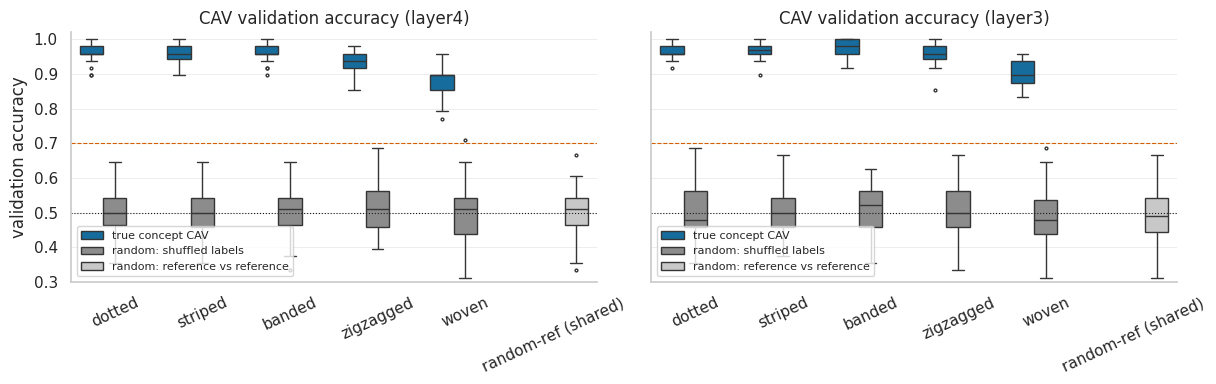

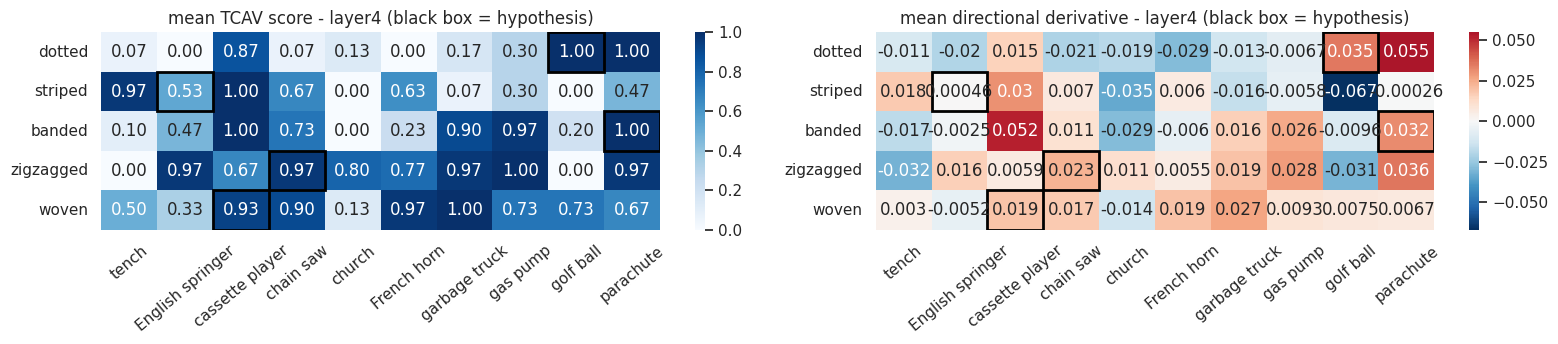

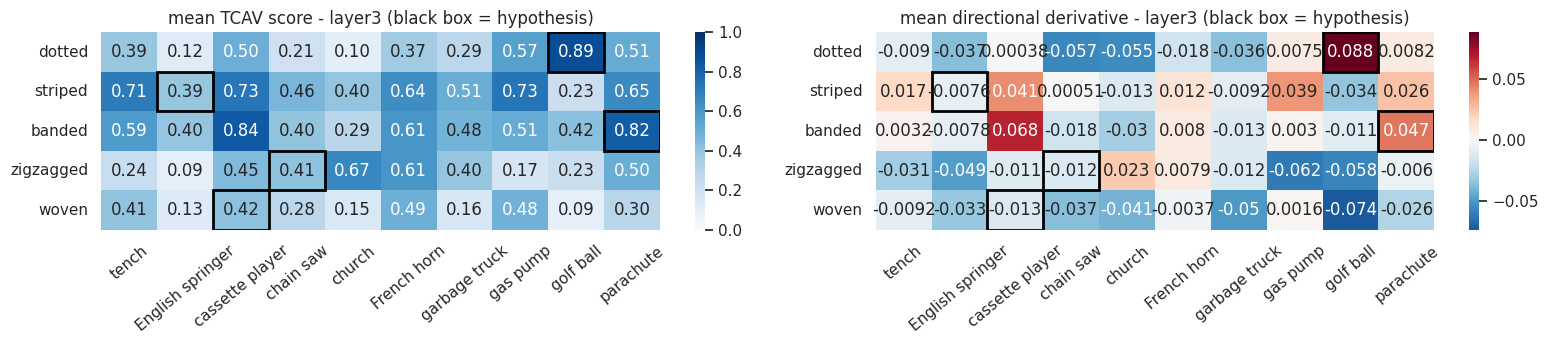

In [63]:
CONCEPT_COLORS = {c: OKABE[i % len(OKABE)] for i, c in enumerate(CFG.CONCEPTS)}
KIND_COLORS = {"concept": "#0072B2", "shuffled_labels": "#8C8C8C", "random_reference": "#C8C8C8"}
KIND_LABELS = {"concept": "true concept CAV", "shuffled_labels": "random: shuffled labels", "random_reference": "random: reference vs reference"}

def savefig(name):
    plt.savefig(CFG.OUT_DIR / name, dpi=200, bbox_inches="tight")

def plot_cav_accuracy():
    d = cav_df.copy()
    d["concept"] = d["concept"].replace({RANDOM_REF_NAME: "random-ref (shared)"})
    fig, axes = plt.subplots(1, len(CFG.TCAV_LAYERS), figsize=(6.2 * len(CFG.TCAV_LAYERS), 4), sharey=True, squeeze=False)
    for ax, layer in zip(axes[0], CFG.TCAV_LAYERS):
        sns.boxplot(data=d[d.layer == layer], x="concept", y="val_acc", hue="kind", hue_order=["concept"] + CFG.CONTROLS,
                    palette=KIND_COLORS, ax=ax, linewidth=1, fliersize=2)
        ax.axhline(0.5, color="k", lw=0.8, ls=":")
        ax.axhline(CFG.CAV_MIN_ACC, color="#D55E00", lw=0.8, ls="--")
        ax.set(title=f"CAV validation accuracy ({layer})", xlabel="", ylabel="validation accuracy", ylim=(0.3, 1.02))
        ax.tick_params(axis="x", rotation=25)
        h, _ = ax.get_legend_handles_labels()
        ax.legend(h, [KIND_LABELS[k] for k in ["concept"] + CFG.CONTROLS], fontsize=8, loc="lower left")
    plt.tight_layout()
    savefig("cav_validation_accuracy.png")
    plt.show()
plot_cav_accuracy()

def concept_class_matrix(layer, value):
    d = res_df[(res_df.layer == layer) & (res_df.kind == "concept")]
    m = d.pivot_table(index="concept", columns="class_idx", values=value, aggfunc="mean").reindex(CFG.CONCEPTS)
    return m.rename(columns=dict(enumerate(CLASS_NAMES)))

def plot_heatmaps(layer):
    fig, axes = plt.subplots(1, 2, figsize=(16, 3.6))
    for ax, value, cmap, title, kw in [
            (axes[0], "tcav", "Blues", "mean TCAV score", dict(vmin=0, vmax=1)),
            (axes[1], "mean_S", "RdBu_r", "mean directional derivative", dict(center=0))]:
        m = concept_class_matrix(layer, value)
        sns.heatmap(m, annot=True, fmt=".2f" if value == "tcav" else ".2g", cmap=cmap, ax=ax, cbar=True, **kw)
        for c, kname in CFG.CONCEPT_CLASS_HYPOTHESES.items():
            ax.add_patch(Rectangle((CLASS_NAMES.index(kname), CFG.CONCEPTS.index(c)), 1, 1, fill=False, edgecolor="black", lw=2))
        ax.set_title(f"{title} - {layer} (black box = hypothesis)")
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", rotation=40)
    plt.tight_layout()
    savefig(f"heatmap_{layer}.png")
    plt.show()
for _l in CFG.TCAV_LAYERS:
    plot_heatmaps(_l)

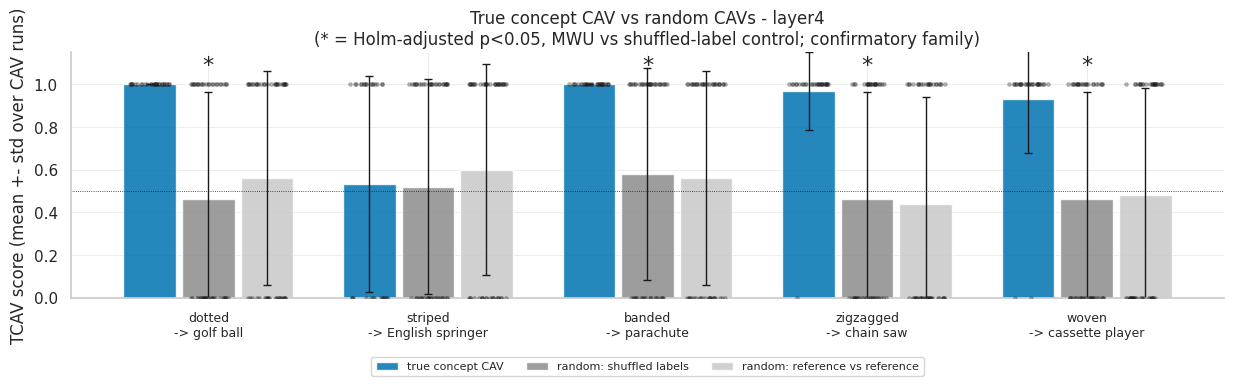

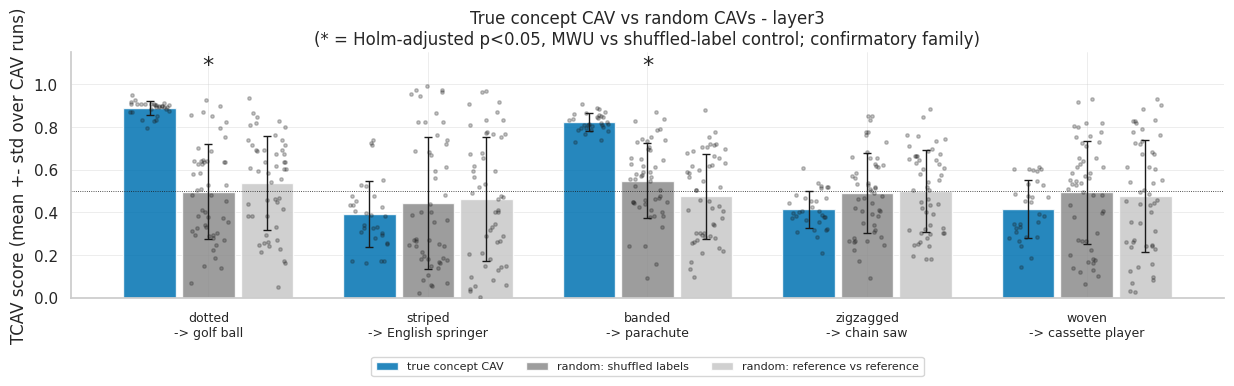

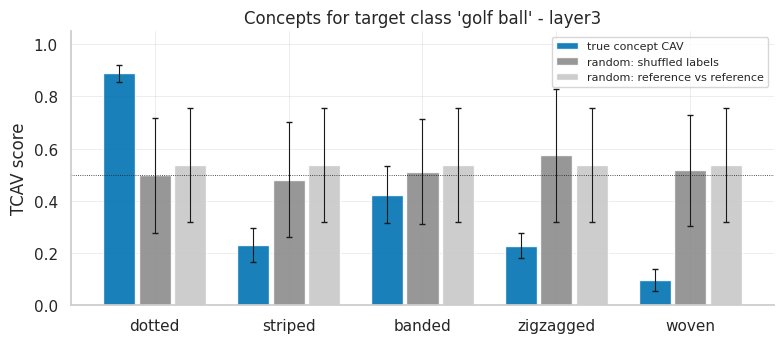

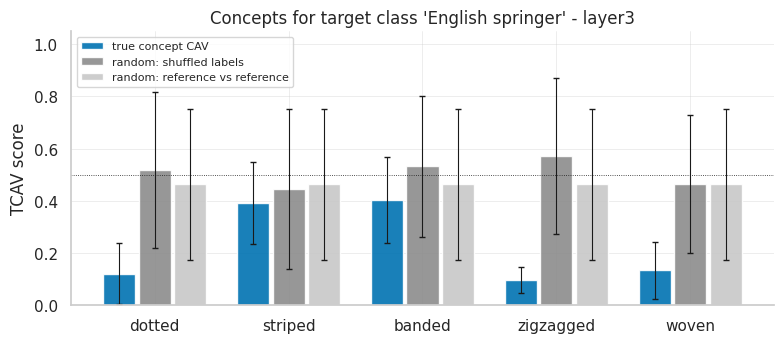

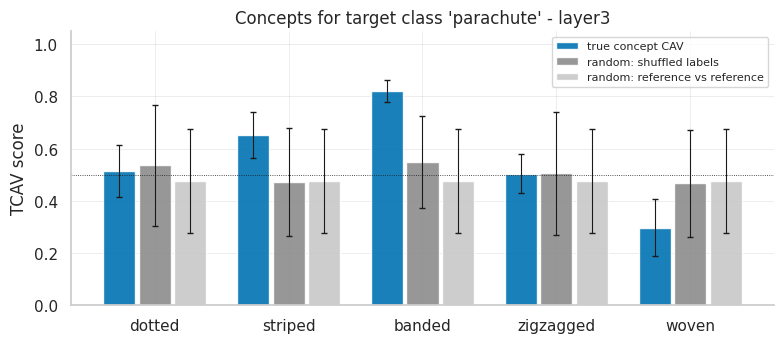

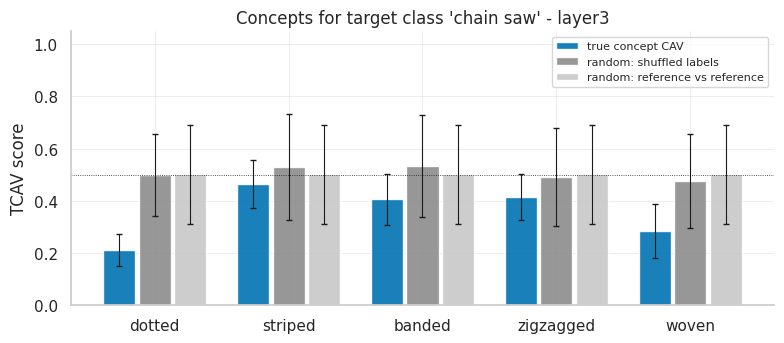

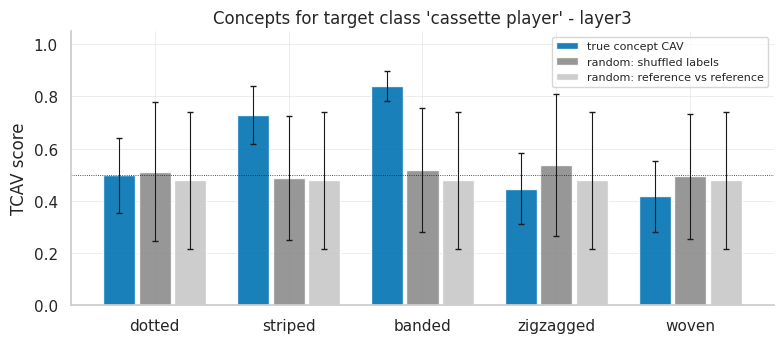

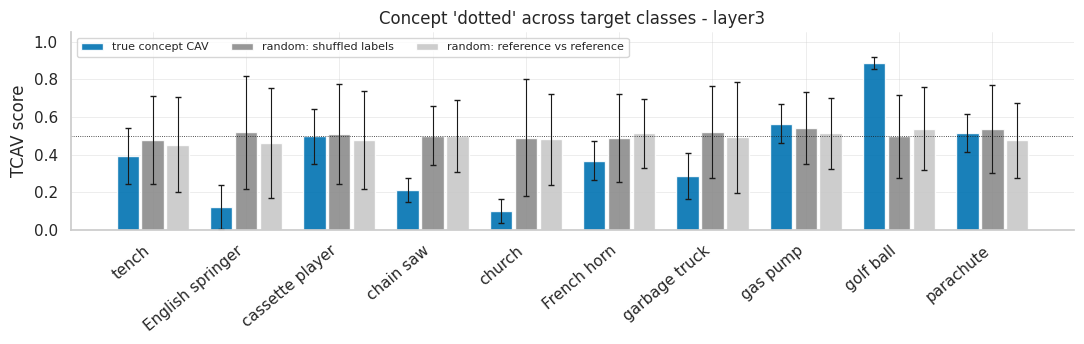

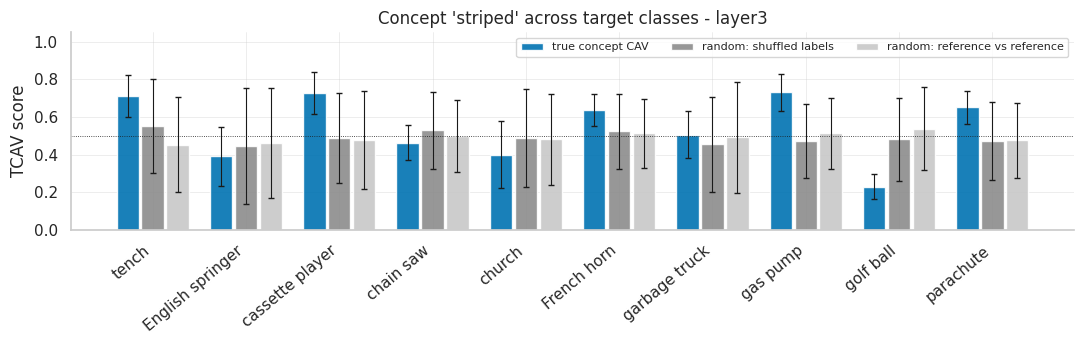

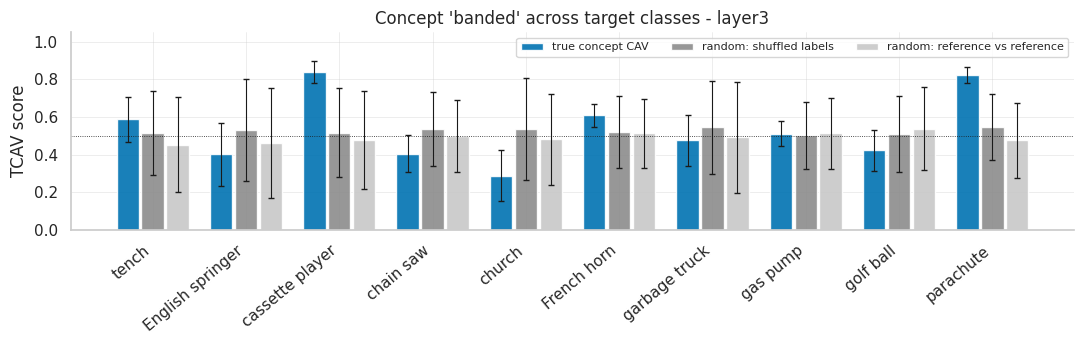

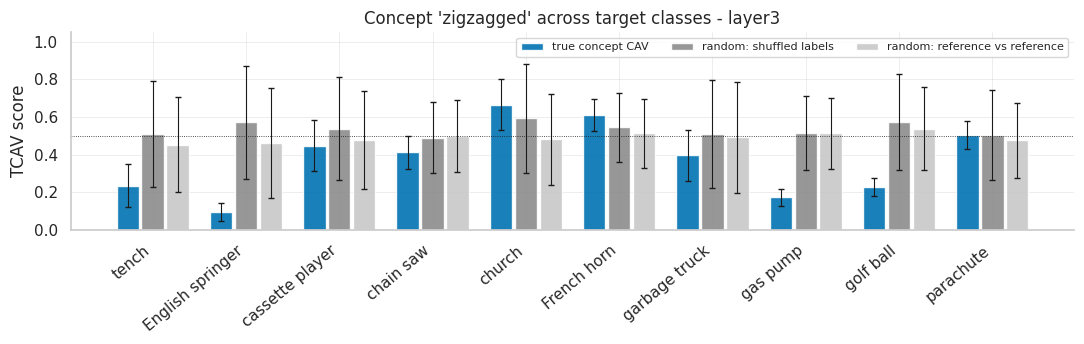

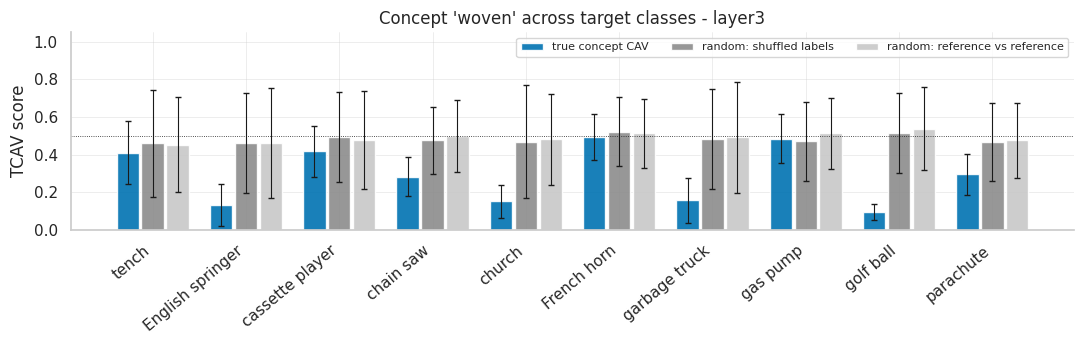

In [64]:
def plot_hypothesis_comparison(layer):
    kinds = ["concept"] + CFG.CONTROLS
    pairs = list(CFG.CONCEPT_CLASS_HYPOTHESES.items())
    fig, ax = plt.subplots(figsize=(1.9 * len(pairs) + 3, 4.2))
    width = 0.8 / len(kinds)
    rng_j = np.random.default_rng(0)
    for i, (c, kname) in enumerate(pairs):
        k = CLASS_NAMES.index(kname)
        for j, kind in enumerate(kinds):
            conc = RANDOM_REF_NAME if kind == "random_reference" else c
            vals = res_df[(res_df.layer == layer) & (res_df.kind == kind) & (res_df.concept == conc) & (res_df.class_idx == k)]["tcav"].values
            if len(vals) == 0:
                continue
            xpos = i + (j - (len(kinds) - 1) / 2) * width
            ax.bar(xpos, vals.mean(), width * 0.9, color=KIND_COLORS[kind], alpha=0.85, label=KIND_LABELS[kind] if i == 0 else None)
            ax.errorbar(xpos, vals.mean(), yerr=vals.std(ddof=1) if len(vals) > 1 else 0, color="k", capsize=3, lw=1)
            ax.scatter(xpos + rng_j.uniform(-width / 3, width / 3, len(vals)), vals, s=6, color="k", alpha=0.25, zorder=3)
        s = stats_confirmatory[(stats_confirmatory.layer == layer) & (stats_confirmatory.concept == c) &
                               (stats_confirmatory.class_idx == k) & (stats_confirmatory.control == "shuffled_labels")]
        if len(s) and bool(s["supported_holm"].iloc[0]):
            ax.text(i, 1.06, "*", ha="center", fontsize=16)
    ax.set_xticks(range(len(pairs)))
    ax.set_xticklabels([f"{c}\n-> {k}" for c, k in pairs], fontsize=9)
    ax.set(ylim=(0, 1.15), ylabel="TCAV score (mean +- std over CAV runs)",
           title=f"True concept CAV vs random CAVs - {layer}\n(* = Holm-adjusted p<{CFG.ALPHA}, MWU vs shuffled-label control; confirmatory family)")
    ax.axhline(0.5, color="k", lw=0.6, ls=":")
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=len(kinds))
    plt.tight_layout()
    savefig(f"hypothesis_vs_random_{layer}.png")
    plt.show()
for _l in CFG.TCAV_LAYERS:
    plot_hypothesis_comparison(_l)

summ = res_df.groupby(["layer", "kind", "concept", "class_idx"])["tcav"].agg(["mean", "std", "count"]).reset_index()

def _bars(ax, labels, get, kinds):
    width = 0.8 / len(kinds)
    for j, kind in enumerate(kinds):
        means, errs = [], []
        for lab in labels:
            r = get(kind, lab)
            means.append(r["mean"].iloc[0] if len(r) else np.nan)
            errs.append(r["std"].iloc[0] if len(r) else np.nan)
        x = np.arange(len(labels)) + (j - (len(kinds) - 1) / 2) * width
        ax.bar(x, means, width * 0.9, yerr=np.nan_to_num(errs), color=KIND_COLORS[kind], alpha=0.9, capsize=2,
               error_kw=dict(lw=0.8), label=KIND_LABELS[kind])
    ax.set_xticks(range(len(labels)))
    ax.set_ylim(0, 1.05)
    ax.axhline(0.5, color="k", lw=0.6, ls=":")

def plot_concepts_for_class(layer, class_name):
    k = CLASS_NAMES.index(class_name)
    kinds = ["concept"] + CFG.CONTROLS
    fig, ax = plt.subplots(figsize=(8, 3.6))
    def get(kind, c):
        conc = RANDOM_REF_NAME if kind == "random_reference" else c
        return summ[(summ.layer == layer) & (summ.kind == kind) & (summ.concept == conc) & (summ.class_idx == k)]
    _bars(ax, CFG.CONCEPTS, get, kinds)
    ax.set_xticklabels(CFG.CONCEPTS)
    ax.set(ylabel="TCAV score", title=f"Concepts for target class '{class_name}' - {layer}")
    ax.legend(fontsize=8)
    plt.tight_layout()
    savefig(f"concepts_for_{class_name.replace(' ', '_')}_{layer}.png")
    plt.show()

def plot_concept_across_classes(layer, concept):
    kinds = ["concept"] + CFG.CONTROLS
    fig, ax = plt.subplots(figsize=(11, 3.6))
    def get(kind, kname):
        k = CLASS_NAMES.index(kname)
        conc = RANDOM_REF_NAME if kind == "random_reference" else concept
        return summ[(summ.layer == layer) & (summ.kind == kind) & (summ.concept == conc) & (summ.class_idx == k)]
    _bars(ax, CLASS_NAMES, get, kinds)
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha="right")
    ax.set(ylabel="TCAV score", title=f"Concept '{concept}' across target classes - {layer}")
    ax.legend(fontsize=8, ncol=3)
    plt.tight_layout()
    savefig(f"concept_{concept}_across_classes_{layer}.png")
    plt.show()

for _kname in dict.fromkeys(CFG.CONCEPT_CLASS_HYPOTHESES.values()):
    plot_concepts_for_class(CFG.PRIMARY_LAYER, _kname)
for _c in CFG.CONCEPTS:
    plot_concept_across_classes(CFG.PRIMARY_LAYER, _c)

## 25. Final observations and interpretation
The cell below prints a summary **computed from the results** (no text is hard-coded). Write your interpretation only after running it, and keep these points in mind:

* **Supported vs exploratory.** Only pairs with Holm-adjusted $p<\alpha$ in the *confirmatory* table are statistically supported (relative to the random-CAV controls and the CAV-sampling variability). Everything in the all-pairs (50 pairs per layer) table is exploratory.
* **A TCAV score near 0 or 1 is not automatically meaningful.** Random CAVs can have scores far from 0.5; always read the score against the random-control distribution.
* **`layer4` pooled features give image-independent gradients** (section 19 check), so single-CAV scores are 0 or 1 and the mean over runs measures how consistently $w_k^\top v_C>0$. Use the mean directional derivative columns and `layer3` as complementary evidence.
* **Concept validity.** DTD concept images are texture close-ups, while target images are object photos; a CAV trained on DTD may partly capture "texture style" rather than the concept as it appears on objects. Low CAV validation accuracy means the concept is not linearly separable at that layer, and such CAVs were discarded.
* Sensitivity to the choice of reference set (`REFERENCE_SOURCE`, `EXTRA_EXCLUDE`) and to `TCAV_ONLY_CORRECT` is worth checking before drawing conclusions.
* TCAV measures *sensitivity of a logit to a direction*, not causal use of the concept by the model.

In [65]:
def print_summary():
    print(f"Test accuracy of fine-tuned ResNet50: {test_res['acc']:.4f}\n")
    for layer in CFG.TCAV_LAYERS:
        cd = cav_df[(cav_df.layer == layer) & (cav_df.kind == "concept")]
        print(f"=== {layer}: {int(cd.valid.sum())}/{len(cd)} concept CAVs passed the validity checks (mean val acc {cd.val_acc.mean():.3f}) ===")
        for control in CFG.CONTROLS:
            s = stats_confirmatory[(stats_confirmatory.layer == layer) & (stats_confirmatory.control == control)]
            for _, r in s.iterrows():
                verdict = "SUPPORTED" if r.supported_holm else "not supported"
                print(f"  [{control:16s}] {r.concept:>9s} -> {r.class_name:<16s} TCAV {r.mean_actual:.3f}+-{r.std_actual:.3f} vs control {r.mean_control:.3f}+-{r.std_control:.3f} | Holm p={r.p_mwu_tcav_holm:.3g} | {verdict} ({r.direction})")
        ex = stats_exploratory[(stats_exploratory.layer == layer) & (stats_exploratory.control == "shuffled_labels")]
        print(f"  exploratory: {int(ex.supported_holm.sum())}/{len(ex)} concept-class pairs have Holm p<{CFG.ALPHA} vs shuffled-label control (exploratory, not confirmatory)\n")
print_summary()

Test accuracy of fine-tuned ResNet50: 0.9924

=== layer4: 150/150 concept CAVs passed the validity checks (mean val acc 0.939) ===
  [shuffled_labels ]    dotted -> golf ball        TCAV 1.000+-0.000 vs control 0.460+-0.503 | Holm p=4.6e-06 | SUPPORTED (above control)
  [shuffled_labels ]   striped -> English springer TCAV 0.533+-0.507 vs control 0.520+-0.505 | Holm p=0.913 | not supported (above control)
  [shuffled_labels ]    banded -> parachute        TCAV 1.000+-0.000 vs control 0.580+-0.499 | Holm p=8.23e-05 | SUPPORTED (above control)
  [shuffled_labels ] zigzagged -> chain saw        TCAV 0.967+-0.183 vs control 0.460+-0.503 | Holm p=2e-05 | SUPPORTED (above control)
  [shuffled_labels ]     woven -> cassette player  TCAV 0.933+-0.254 vs control 0.460+-0.503 | Holm p=6.98e-05 | SUPPORTED (above control)
  [random_reference]    dotted -> golf ball        TCAV 1.000+-0.000 vs control 0.560+-0.501 | Holm p=9.19e-05 | SUPPORTED (above control)
  [random_reference]   striped -> Engl

## 26. Saving results and model checkpoints
Everything is written to `tcav_outputs/` (and optionally copied to Google Drive with `CFG.SAVE_TO_DRIVE = True`).

In [66]:
cav_df.to_csv(CFG.OUT_DIR / "cav_runs.csv", index=False)
res_df.to_csv(CFG.OUT_DIR / "tcav_results_per_run.csv", index=False)
stats_exploratory.to_csv(CFG.OUT_DIR / "stats_exploratory_all_pairs.csv", index=False)
stats_confirmatory.to_csv(CFG.OUT_DIR / "stats_confirmatory_hypotheses.csv", index=False)
pd.DataFrame({"y_true": test_res["labels"], "y_pred": test_res["preds"], "path": test_paths}).to_csv(CFG.OUT_DIR / "test_predictions.csv", index=False)
with open(CFG.OUT_DIR / "test_metrics.json", "w") as f:
    json.dump({"test_acc": test_res["acc"], "test_loss": test_res["loss"], "val_acc": val_res["acc"], "val_loss": val_res["loss"]}, f, indent=2)

cfg_dict = {k: (str(v) if isinstance(v, Path) else v) for k, v in vars(CFG).items() if not k.startswith("__")}
with open(CFG.OUT_DIR / "config.json", "w") as f:
    json.dump(cfg_dict, f, indent=2, default=str)

print("Saved to", CFG.OUT_DIR)
print(sorted(p.name for p in CFG.OUT_DIR.iterdir()))

if CFG.SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(CFG.OUT_DIR, CFG.DRIVE_DIR, dirs_exist_ok=True)
    print("Copied outputs to", CFG.DRIVE_DIR)

Saved to /content/tcav_outputs
['cav_runs.csv', 'cav_validation_accuracy.png', 'concept_banded_across_classes_layer3.png', 'concept_dotted_across_classes_layer3.png', 'concept_striped_across_classes_layer3.png', 'concept_woven_across_classes_layer3.png', 'concept_zigzagged_across_classes_layer3.png', 'concepts_for_English_springer_layer3.png', 'concepts_for_cassette_player_layer3.png', 'concepts_for_chain_saw_layer3.png', 'concepts_for_golf_ball_layer3.png', 'concepts_for_parachute_layer3.png', 'config.json', 'confusion_matrix.png', 'heatmap_layer3.png', 'heatmap_layer4.png', 'hypothesis_vs_random_layer3.png', 'hypothesis_vs_random_layer4.png', 'resnet50_imagenette_best.pt', 'stats_confirmatory_hypotheses.csv', 'stats_exploratory_all_pairs.csv', 'tcav_results_per_run.csv', 'test_metrics.json', 'test_predictions.csv', 'training_curves.png', 'training_history.json']
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=T